## ChatBot With Tool

In [19]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [20]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-120b")

In [21]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

In [22]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [23]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [24]:
tools=[tool,multiply]
llm_with_tool=llm.bind_tools(tools)
llm_with_tool 

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.2', 'langchain': '1.5.0', 'langchain-groq': '1.2.0'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x128c2ad50>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x128cc4e10>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive,

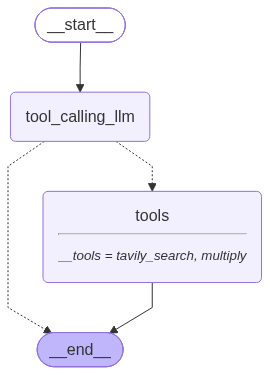

In [25]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [26]:
response=graph.invoke({"messages":"What is the recent ai news"})
response['messages'][-1].content

'{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blogs.oracle.com/ai-and-datascience/whats-new-in-ai-november-2026", "title": "What\'s New in Oracle AI? November 2026 Edition", "content": "Product Marketing Director, Oracle Data and AI\\n\\nOracle AI World brought a busy October for AI at OCI, with announcements spanning our expanded OpenAI collaboration, Oracle AI Media Models in preview, and new ways to build and scale agentic applications. In November’s roundup, explore these highlights alongside the latest OCI Enterprise AI updates, our recognition as a Leader in the IDC MarketScape for Agentic AI Platforms, and on demand AI World replays for sessions that you may have missed.\\n\\n## New updates and features\\n\\n### Oracle and OpenAI bring frontier AI into everyday business\\n\\nOracle announced an expanded collaboration with OpenAI, connecting Oracle’s enterprise technology with ChatGPT, Codex, and

In [27]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_00b4214d-ba06-421d-969f-b48b3e134508)
 Call ID: fc_00b4214d-ba06-421d-969f-b48b3e134508
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blogs.oracle.com/ai-and-datascience/whats-new-in-ai-november-2026", "title": "What's New in Oracle AI? November 2026 Edition", "content": "Product Marketing Director, Oracle Data and AI\n\nOracle AI World brought a busy October for AI at OCI, with announcements spanning our expanded OpenAI collaboration, Oracle AI Media Models in preview, and new ways to buil

In [29]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [30]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_6964f273-079a-4e2c-a5e3-26c36614944b)
 Call ID: fc_6964f273-079a-4e2c-a5e3-26c36614944b
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blogs.oracle.com/ai-and-datascience/whats-new-in-ai-november-2026", "title": "What's New in Oracle AI? November 2026 Edition", "content": "Product Marketing Director, Oracle Data and AI\n\nOracle AI World brought a busy October for AI at OCI, with announcements spanning our expanded OpenAI collaboration, Oracle AI Media Models in pre

## ReAct Agent Architecture

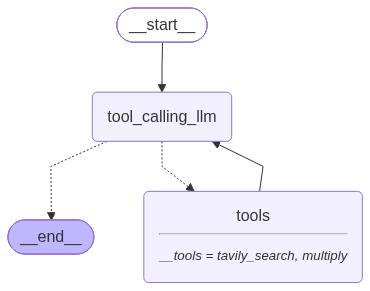

In [32]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [33]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_0dca06f1-863b-4e12-b795-069209926c7d)
 Call ID: fc_0dca06f1-863b-4e12-b795-069209926c7d
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.riskinfo.ai/post/ai-insights-key-global-developments-in-november-2026", "title": "AI Insights: Key Global Developments in November 2026", "content": "In the defence sector, Shield AI announced plans to acquire radar developer Echodyne in a $5.3 billion deal, alongside a $2.5 billion funding round that valued the company at $28.8 b